# Importaciones necesarias

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, auc, ConfusionMatrixDisplay

# Carga y exploración de datos

Procedemos a importar el archivo y revisamos las primeras filas del dataset para familiarizarnos con los datos. 

In [5]:
df = pd.read_csv('dataset.csv')

display(df.head())
print("\n--- Información del Dataset ---")
df.info()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



--- Información del Dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


Además, procedemos a eliminar las columnas que no aportan al modelo predictivo o son demasiados complejas de procesar ahora

In [6]:
df = df.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'], errors='ignore')

#  Preprocesamiento de los datos

El primero paso será ver si en el conjunto de datos hay valores faltantes. 

In [7]:
df.isna().sum()

Survived      0
Pclass        0
Sex           0
Age         177
SibSp         0
Parch         0
Fare          0
Embarked      2
dtype: int64

Vemos que falta algunos datos así que procedemos a imputarlos. 

In [8]:
mediana_edad = df['Age'].median()
df['Age'] = df['Age'].fillna(mediana_edad)

moda_embarked = df['Embarked'].mode()[0]
df['Embarked'] = df['Embarked'].fillna(moda_embarked)

print("\nValores nulos después de la imputación:")
print(df.isnull().sum())


Valores nulos después de la imputación:
Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64


Tras esto, vamos a codificar las variables categóricas y escalar las variables numéricas.

In [11]:
numeric_features = ['Age', 'SibSp', 'Parch', 'Fare']
categorical_features = ['Pclass', 'Sex', 'Embarked']

numeric_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

# División del dataset
Tras preprocesar la información vamos a dividir el conjunto de datos en uno de entrenamiento y otro en conjunto de prueba. 

In [12]:
X = df.drop(columns=['Survived'])
y = df['Survived']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Tamaño del set de entrenamiento: {X_train.shape[0]} filas")
print(f"Tamaño del set de prueba: {X_test.shape[0]} filas")

Tamaño del set de entrenamiento: 712 filas
Tamaño del set de prueba: 179 filas


# Implementación de modelos

Vamos a implementar y entrenar cinco modelos de clasificación: 

- Regresión logística
- K-Nearest Neighbors (KNN)
- Support Vector Classifier (SVC)
- Árbol de decisión (DecisionTreeClassifier)
- Random Forest

In [13]:
modelos = {
    'Regresión Logística': LogisticRegression(random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    # probability=True es crucial en SVC para poder dibujar la curva ROC después
    'SVC': SVC(probability=True, random_state=42),
    'Árbol de Decisión': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
}

pipelines = {}

# Crear pipeline y entrenar cada modelo
for nombre, modelo in modelos.items():
    clf = Pipeline(steps=[
        ('preprocessor', preprocessor), 
        ('classifier', modelo)
    ])
    
    # Entrenamiento
    clf.fit(X_train, y_train)
    pipelines[nombre] = clf
    print(f"[{nombre}] - Modelo entrenado exitosamente.")

[Regresión Logística] - Modelo entrenado exitosamente.
[KNN] - Modelo entrenado exitosamente.
[SVC] - Modelo entrenado exitosamente.
[Árbol de Decisión] - Modelo entrenado exitosamente.
[Random Forest] - Modelo entrenado exitosamente.


# Evaluación de los modelos
Tras implementarlos y el entrenamiento procedemos a evaluarlos mediante diferentes métricas de rendimiento. Para ello visualizaremos las métricas utilizando dos gráficos:
- Matriz de confusión
- Curva ROC


EVALUACIÓN: Regresión Logística
Exactitud (Accuracy): 0.7989

Reporte de Clasificación:
              precision    recall  f1-score   support

           0       0.81      0.86      0.83       105
           1       0.78      0.72      0.75        74

    accuracy                           0.80       179
   macro avg       0.80      0.79      0.79       179
weighted avg       0.80      0.80      0.80       179



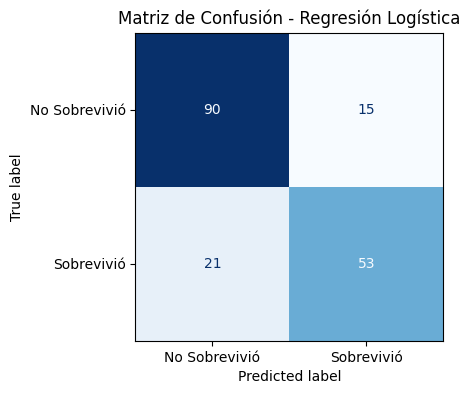


EVALUACIÓN: KNN
Exactitud (Accuracy): 0.8156

Reporte de Clasificación:
              precision    recall  f1-score   support

           0       0.82      0.88      0.85       105
           1       0.81      0.73      0.77        74

    accuracy                           0.82       179
   macro avg       0.81      0.80      0.81       179
weighted avg       0.82      0.82      0.81       179



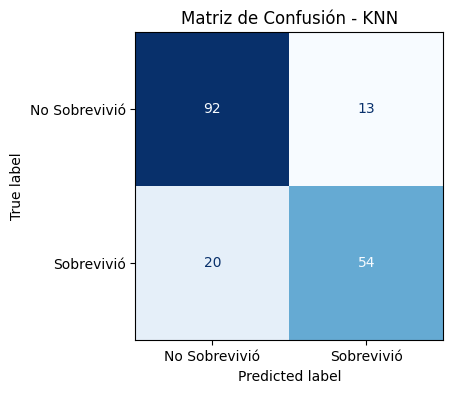


EVALUACIÓN: SVC
Exactitud (Accuracy): 0.8156

Reporte de Clasificación:
              precision    recall  f1-score   support

           0       0.82      0.88      0.85       105
           1       0.81      0.73      0.77        74

    accuracy                           0.82       179
   macro avg       0.81      0.80      0.81       179
weighted avg       0.82      0.82      0.81       179



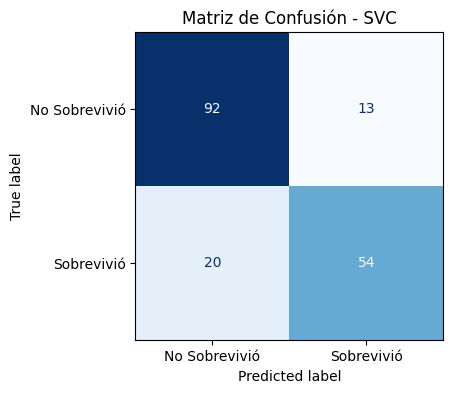


EVALUACIÓN: Árbol de Decisión
Exactitud (Accuracy): 0.7933

Reporte de Clasificación:
              precision    recall  f1-score   support

           0       0.84      0.80      0.82       105
           1       0.73      0.78      0.76        74

    accuracy                           0.79       179
   macro avg       0.79      0.79      0.79       179
weighted avg       0.80      0.79      0.79       179



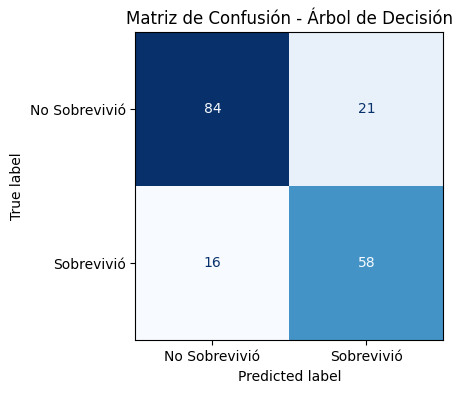


EVALUACIÓN: Random Forest
Exactitud (Accuracy): 0.8101

Reporte de Clasificación:
              precision    recall  f1-score   support

           0       0.80      0.90      0.85       105
           1       0.82      0.69      0.75        74

    accuracy                           0.81       179
   macro avg       0.81      0.79      0.80       179
weighted avg       0.81      0.81      0.81       179



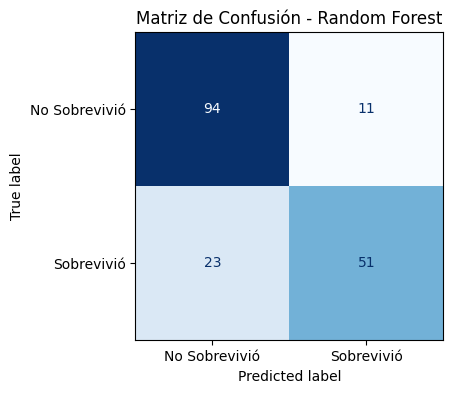

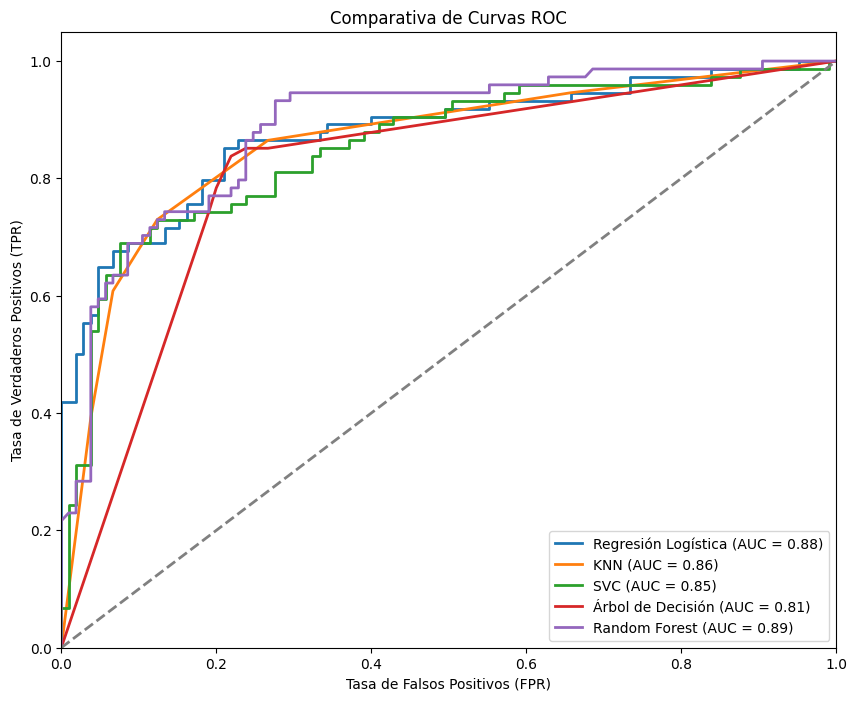

In [17]:
fig_roc, ax_roc = plt.subplots(figsize=(10, 8))

for nombre, clf in pipelines.items():
    print(f"\n" + "="*40)
    print(f"EVALUACIÓN: {nombre}")
    print("="*40)
    
    y_pred = clf.predict(X_test)
    y_proba = clf.predict_proba(X_test)[:, 1]
    
    exactitud = accuracy_score(y_test, y_pred)
    print(f"Exactitud (Accuracy): {exactitud:.4f}\n")
    print("Reporte de Clasificación:")
    print(classification_report(y_test, y_pred, zero_division=0))
    
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_auc = auc(fpr, tpr)
    ax_roc.plot(fpr, tpr, lw=2, label=f'{nombre} (AUC = {roc_auc:.2f})')
    
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Sobrevivió", "Sobrevivió"])
    fig_cm, ax_cm = plt.subplots(figsize=(4, 4))
    disp.plot(cmap='Blues', ax=ax_cm, colorbar=False)
    ax_cm.set_title(f'Matriz de Confusión - {nombre}')
    
    display(fig_cm)
    plt.close(fig_cm)

ax_roc.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
ax_roc.set_xlim([0.0, 1.0])
ax_roc.set_ylim([0.0, 1.05])
ax_roc.set_xlabel('Tasa de Falsos Positivos (FPR)')
ax_roc.set_ylabel('Tasa de Verdaderos Positivos (TPR)')
ax_roc.set_title('Comparativa de Curvas ROC')
ax_roc.legend(loc="lower right")

plt.show()

# Comparativa de rendimientos
Analizando el resultado de las métricas generadas, se puede extraer las siguiente conclusiones:

- Los mejores modelos (Empate): Tanto el K-Nearest Neighbors (KNN) como el Support Vector Classifier (SVC) han obtenido el mejor rendimiento global con una exactitud (Accuracy) del 81.56%. Además, ambos presentan un excelente equilibrio en el F1-score para la clase positiva (sobrevivió), alcanzando un 0.77.

- Un competidor muy cercano: El Random Forest les sigue muy de cerca con una exactitud del 81.01% y un F1-score de 0.75. Como modelo de ensamble, es muy robusto, aunque en este caso concreto se ha quedado un poco por detrás de KNN y SVC.

- La línea base sólida: La Regresión Logística logra un nada despreciable 79.89% de exactitud. Al ser un modelo lineal más sencillo, demuestra que los datos ya tienen una buena separabilidad lineal tras el preprocesamiento.

- El modelo menos eficiente: El Árbol de Decisión puro obtuvo el rendimiento más bajo, con un 79.33% de exactitud y un F1-score de 0.76. Esto es muy habitual en árboles individuales debido a su tendencia natural al sobreajuste (overfitting) con los datos de entrenamiento.